In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
df_india_anal = df[(df['job_country'] == 'India') & (df['job_title_short'] == 'Data Analyst')]

In [19]:
df_location = df_india_anal['job_location'].value_counts().to_frame()

In [21]:
df_location = df_location.drop(index = ['India', 'Anywhere']).head(10)

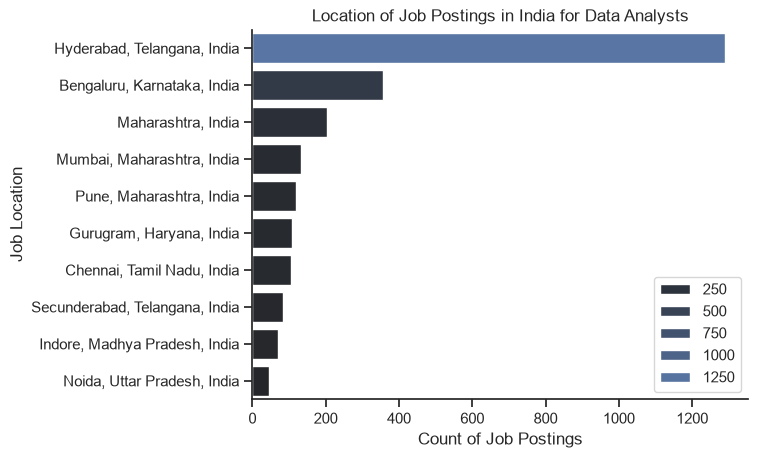

In [44]:
sns.set_theme(style='ticks')
sns.barplot(data=df_location, x='count', y='job_location', hue='count', palette='dark:b')
sns.despine()
plt.xlabel('Count of Job Postings')
plt.ylabel('Job Location')
plt.title('Location of Job Postings in India for Data Analysts')
plt.legend(title='')
plt.show()

In [ ]:
df_wfh = df_india_anal['job_work_from_home'].value_counts().to_frame()

In [ ]:
df_top3 = df_india_anal['job_schedule_type'].value_counts().head(3).to_frame()

In [92]:
df_degree = df_india_anal['job_no_degree_mention'].value_counts().to_frame()
label_map = {
    True : 'No Degree Mentioned',
    False : 'Degree Specified'
}
df_degree.index = df_degree.index.map(label_map)

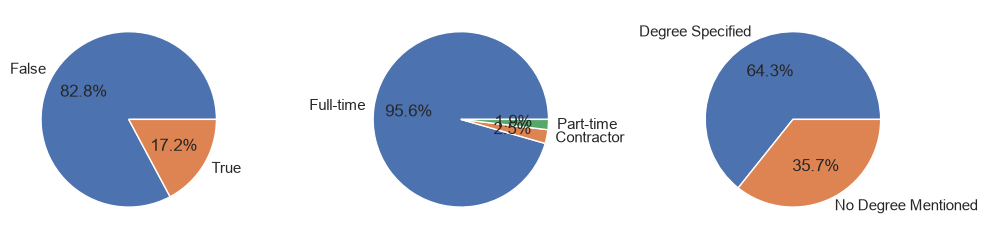

In [93]:
fig, ax = plt.subplots(1, 3, figsize=(10, 15))

df_wfh.plot(kind='pie', ax=ax[0], y='count', legend=False, autopct='%1.1f%%')
df_top3.plot(kind='pie', ax=ax[1], y='count', legend=False, autopct='%1.1f%%')
df_degree.plot(kind='pie', ax=ax[2], y='count', legend=False, autopct='%1.1f%%')

plt.tight_layout()

In [94]:
df_list = [df_wfh, df_top3, df_degree]
titles = ['Work From Home', 'Type of Job Schedule', 'Degree Requirement']

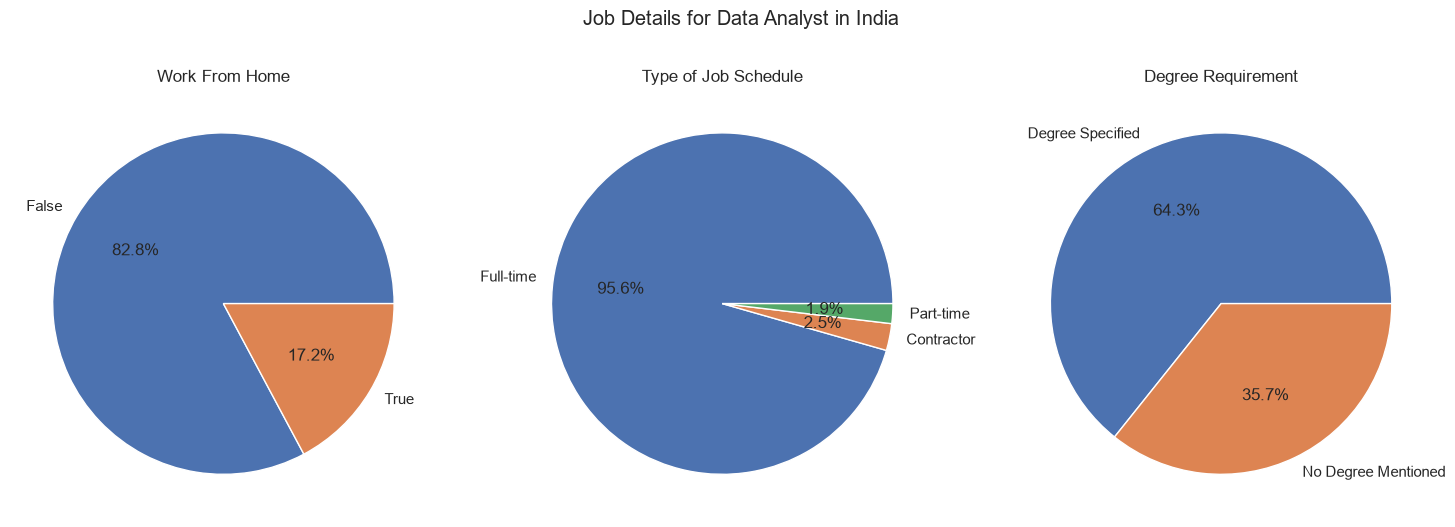

In [112]:
fig, ax = plt.subplots(1, 3, figsize = (15, 5))

fig.suptitle('Job Details for Data Analyst in India', y=1.05)

for i, item in enumerate(df_list) :
    item.plot(kind='pie', ax=ax[i], y='count', legend=False, autopct='%1.1f%%')
    
    ax[i].set_title(titles[i])
    
plt.tight_layout()
plt.show()

In [117]:
df_company = df_india_anal['company_name'].value_counts().head(10).to_frame()

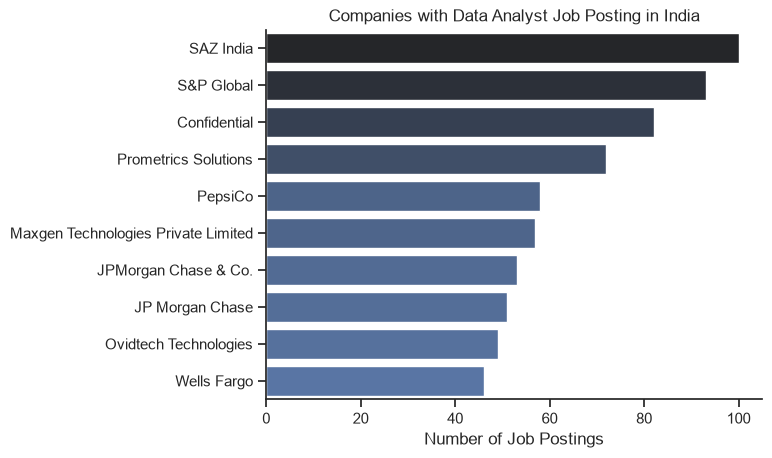

In [129]:
sns.set_theme(style='ticks')
sns.barplot(data=df_company, y='company_name', x='count', palette='dark:b_r', hue='count', legend=False)
sns.despine()
plt.xlabel('Number of Job Postings')
plt.ylabel('')
plt.title('Companies with Data Analyst Job Posting in India')
plt.show()